In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import math

# Coarse temperature scan for L=40/60/80/100

According to Morten's notes, what we are looking for: For the two-dimensional case, we move from a phase with finite magnetization ⟨M⟩ ̸=0 to a paramagnetic phase with ⟨M⟩=0 at a critical temperature TC. At the critical temperature, quantities like the heat capacity CV and the susceptibility χ are discontinuous or diverge at the critical point in the thermodynamic limit, i.e., with an infinitely large lattice (citation: Morten's lecture notes, will cite more properly in report)

So in my graphs I'm looking for the magnetisation going to zero, and the two fancy quantities diverging or so.

In [ ]:
L = [40, 60, 80, 100]

output = pd.DataFrame(columns=['L', 'temp', 'mean epsilon', 'mean mag', 'CV', 'Xi'])

for i in range(len(L)):
    l = L[i]

    for temp in np.arange(2.10, 2.4, 0.03):
        #Read in files based on temp, needs some rounding
        t = format(temp,'.2f')
        filepath = f'..\Outputs\Phase transitions coarse\PhaseTrans_L{l}_T{t}0000_unordered_n10e6.txt'
        data = pd.read_csv(filepath)

        #Compute quantities of interest
        exp_e = data['epsilon'].mean()
        exp_m = data[' abs(m)'].mean()
        data['epsilon squared'] = data['epsilon']*data['epsilon']
        data['mag squared'] = data[' abs(m)']*data[' abs(m)']
        CV = np.square(l)*(1/np.square(temp))*(data['epsilon squared'].mean() - np.square(exp_e))
        Xi = np.square(l)*(1/temp)*(data['mag squared'].mean() - np.square(exp_m))

        #Write to df
        new =  pd.DataFrame([{'L': l, 'temp': temp, 'mean epsilon': exp_e, 'mean mag': exp_m, 'CV': CV, 'Xi': Xi}])
        output = pd.concat([output, new], ignore_index=True)

<>:11: SyntaxWarning: invalid escape sequence '\O'
<>:11: SyntaxWarning: invalid escape sequence '\O'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_13072\2012097823.py:11: SyntaxWarning: invalid escape sequence '\O'
  filepath = f'..\Outputs\PhaseTrans_L{l}_T{t}0000_unordered_n10e6.txt'
C:\Users\bhaan\AppData\Local\Temp\ipykernel_13072\2012097823.py:24: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  output = pd.concat([output, new], ignore_index=True)


In [16]:
L40 = output[output['L']==40]
L60 = output[output['L']==60]
L80 = output[output['L']==80]
L100 = output[output['L']==100]

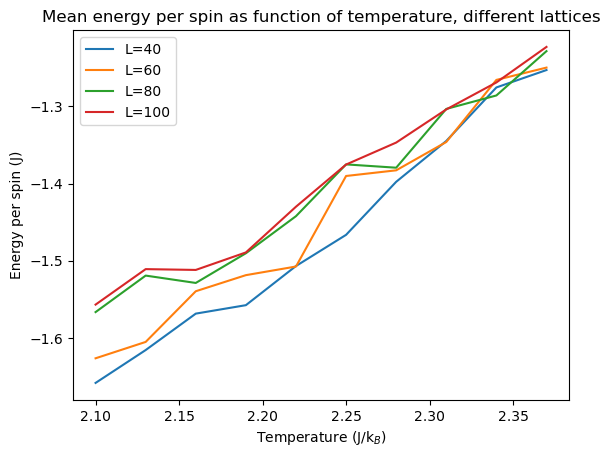

In [17]:
plt.plot(L40['temp'], L40['mean epsilon'], label='L=40')
plt.plot(L60['temp'], L60['mean epsilon'], label='L=60')
plt.plot(L80['temp'], L80['mean epsilon'], label='L=80')
plt.plot(L100['temp'], L100['mean epsilon'], label='L=100')
plt.title('Mean energy per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Energy per spin (J)')
plt.legend()

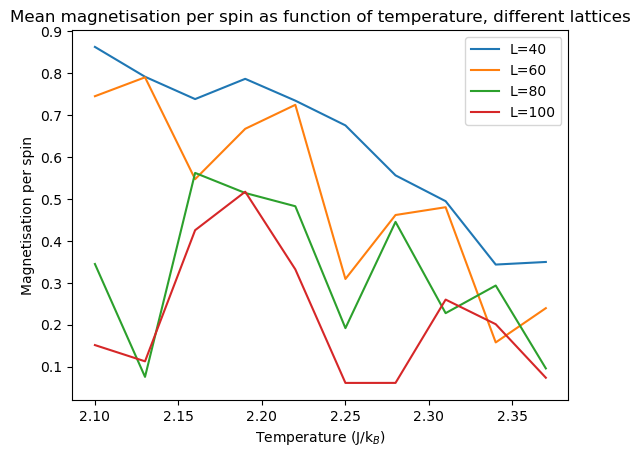

In [23]:
plt.plot(L40['temp'], L40['mean mag'], label='L=40')
plt.plot(L60['temp'], L60['mean mag'], label='L=60')
plt.plot(L80['temp'], L80['mean mag'], label='L=80')
plt.plot(L100['temp'], L100['mean mag'], label='L=100')
plt.title('Mean magnetisation per spin as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Magnetisation per spin')
plt.legend()

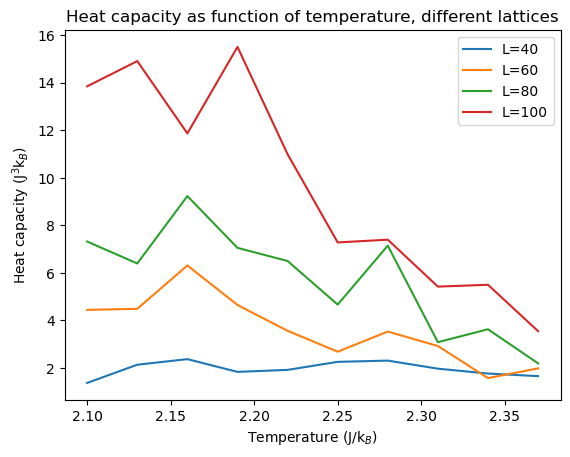

In [22]:
plt.plot(L40['temp'], L40['CV'], label='L=40')
plt.plot(L60['temp'], L60['CV'], label='L=60')
plt.plot(L80['temp'], L80['CV'], label='L=80')
plt.plot(L100['temp'], L100['CV'], label='L=100')
plt.title('Heat capacity as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel(r'Heat capacity (J$^3$k$_B$)')
plt.legend()

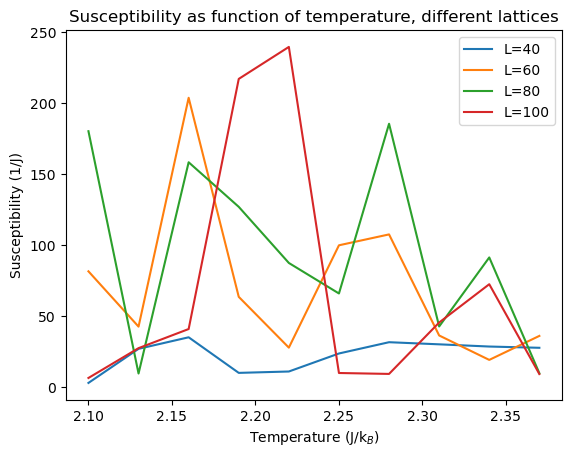

In [21]:
plt.plot(L40['temp'], L40['Xi'], label='L=40')
plt.plot(L60['temp'], L60['Xi'], label='L=60')
plt.plot(L80['temp'], L80['Xi'], label='L=80')
plt.plot(L100['temp'], L100['Xi'], label='L=100')
plt.title('Susceptibility as function of temperature, different lattices')
plt.xlabel(r'Temperature (J/k$_B$)')
plt.ylabel('Susceptibility (1/J)')
plt.legend()

Looking mostly at mag, I'd say that my candidates are:

- 2.12-2.15

- 2.15-2.18

- 2.22-2.28

Run these with a step size of 0.003, should give me about 10 steps for each (can do the first two together).